In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
boite_gs = (-65, -55, 34, 42)
passages = pd.read_csv("/home/nora/projects/NeurOST/my_work/scripts/passages_GS.csv", parse_dates=["t_debut", "t_fin"])

In [3]:
def extraire_passage(fichier, boite):
    """Renvoie deux dicts : nadir (entrée) et karin (cible), points dans la boîte."""
    lon_min, lon_max, lat_min, lat_max = boite

    ds = xr.open_dataset(fichier)
    lon = (ds["longitude"].values + 180) % 360 - 180
    lat = ds["latitude"].values
    ssh = (ds["ssha_unfiltered"].values
           - ds["LongWavelenghtError_cnst_swot_karin"].values
           - ds["LongWavelenghtError_lin_swot_karin"].values)
    temps = ds["time"].values                      # (num_lines,)

    dans_boite = ((lon > lon_min) & (lon < lon_max) &
                  (lat > lat_min) & (lat < lat_max) &
                  np.isfinite(ssh))

    lignes = ds["i_num_line"].values
    pixels = ds["i_num_pixel"].values
    est_nadir = np.zeros(ssh.shape, dtype=bool)
    est_nadir[lignes, pixels] = True

    karin_ok = dans_boite & ~est_nadir
    nadir_ok = dans_boite & est_nadir

    # TODO 1 : temps en 2D, pour avoir un temps par case
    # temps a la forme (num_lines,), il faut le répéter sur les 69 pixels
    # indice : np.repeat(temps[:, None], ssh.shape[1], axis=1)
    temps_2d = np.repeat(temps[:, None], ssh.shape[1], axis=1)

    # TODO 2 : garder les points nadir (lon, lat, ssh, temps) avec le masque nadir_ok
    nadir = {
        "lon": lon[nadir_ok],
        "lat": lat[nadir_ok],
        "ssh": ssh[nadir_ok],
        "temps": temps_2d[nadir_ok]
    }

    # TODO 3 : pareil pour KaRIn avec karin_ok
    karin = {
        "lon": lon[karin_ok],
        "lat": lat[karin_ok],
        "ssh": ssh[karin_ok]
    }

    ds.close()
    return nadir, karin

In [4]:
#Test sur le passage 451 (10/02/2024)

ligne = passages[(passages["cycle"] == 10) & (passages["passe"] == 451)].iloc[0]
nadir, karin = extraire_passage(ligne["fichier"], boite_gs)

print("nadir :", len(nadir["ssh"]), "points")    # attendu : 129
print("karin :", len(karin["ssh"]), "points")    # attendu : 24017

nadir : 129 points
karin : 24017 points


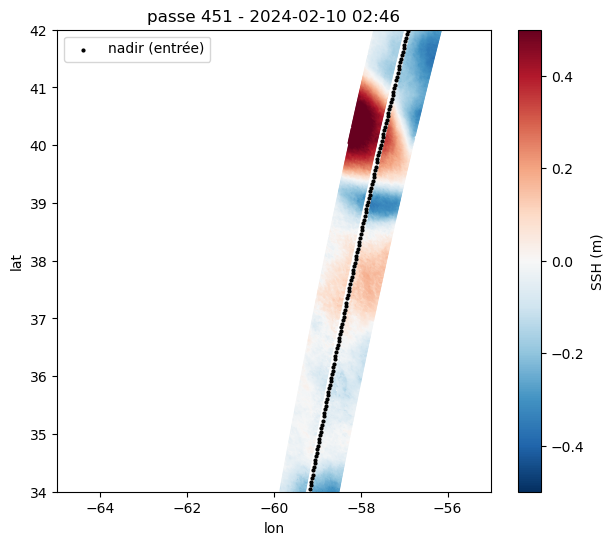

In [5]:
# carte de vérification
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.scatter(karin["lon"], karin["lat"], c=karin["ssh"], s=1,
                cmap="RdBu_r", vmin=-0.5, vmax=0.5)
ax.scatter(nadir["lon"], nadir["lat"], c="k", s=4, label="nadir (entrée)")
plt.colorbar(im, label="SSH (m)")
ax.set_xlim(boite_gs[0], boite_gs[1])
ax.set_ylim(boite_gs[2], boite_gs[3])
ax.set_xlabel("lon")
ax.set_ylabel("lat")
ax.set_title(f"passe {ligne['passe']} - {ligne['t_debut']:%Y-%m-%d %H:%M}")
ax.legend()
plt.show()

In [6]:
import sys
sys.path.append("/home/nora/projects/NeurOST/")     # le dossier qui contient src/
from src.interp_utils import ll2xyz, transformer_ll2xyz

coord_grids = np.load("/home/nora/projects/NeurOST/input_data/coord_grids_gulfstream.npy")
print(coord_grids.shape)     # attendu : (nb_patches, 128, 128, 2)

(44, 128, 128, 2)


In [7]:
def centre_patch(coord_grids, r):
    """lon0, lat0 du patch r, calculés comme dans get_ssh_h5."""
    # TODO 1 : moyenne des 4 cases centrales (63,63), (63,64), (64,63), (64,64)
    # coord_grids[r, i, j, 0] = lon ; coord_grids[r, i, j, 1] = lat
    mid = 128//2
    neighbors = [(r, mid-1, mid-1), (r, mid-1, mid), (r, mid, mid-1), (r, mid, mid)]
    lon0 = np.mean([coord_grids[neighbor[0], neighbor[1], neighbor[2], 0] for neighbor in neighbors])
    lat0 = np.mean([coord_grids[neighbor[0], neighbor[1], neighbor[2], 1] for neighbor in neighbors])
    
    return lon0, lat0

In [8]:
def projeter(lon, lat, lon0, lat0, L=960e3):
    """(lon, lat) -> (x, y) en MÈTRES sur la feuille centrée en (lon0, lat0), comme get_ssh_h5.
    Renvoie aussi le masque `dedans` des points qui tombent dans la feuille L x L."""
    lon_decale = (lon - lon0 + 180) % 360 - 180
    x, y, z = ll2xyz(lat, lon_decale, 0, lat0, 0, 0, transformer_ll2xyz)
    dedans = (z > -1e6) & (np.abs(x) < L / 2) & (np.abs(y) < L / 2)
    return x, y, dedans

In [9]:
for r in range(coord_grids.shape[0]):
    lon0, lat0 = centre_patch(coord_grids, r)
    x, y, dedans = projeter(nadir["lon"], nadir["lat"], lon0, lat0)
    print(r, round(lon0, 1), round(lat0, 1), dedans.sum())

0 -66.4 30.7 0
1 -63.8 30.7 15
2 -61.2 30.7 16
3 -58.6 30.7 16
4 -56.0 30.7 15
5 -53.4 30.7 0
6 -68.9 33.0 0
7 -66.2 33.0 0
8 -63.6 33.0 51
9 -60.9 33.0 52
10 -58.2 33.0 53
11 -55.5 33.0 52
12 -52.8 33.0 0
13 -68.6 35.2 0
14 -65.9 35.2 0
15 -63.1 35.2 88
16 -60.4 35.2 89
17 -57.6 35.2 90
18 -54.9 35.2 89
19 -52.1 35.2 0
20 -68.1 37.5 0
21 -65.3 37.5 0
22 -62.4 37.5 125
23 -59.6 37.5 126
24 -56.8 37.5 127
25 -54.0 37.5 125
26 -51.1 37.5 0
27 -67.4 39.8 0
28 -64.5 39.8 0
29 -61.6 39.8 106
30 -58.6 39.8 105
31 -55.7 39.8 106
32 -52.8 39.8 71
33 -66.5 42.1 0
34 -63.4 42.1 19
35 -60.4 42.1 69
36 -57.4 42.1 68
37 -54.4 42.1 69
38 -51.3 42.1 9
39 -68.4 44.4 0
40 -62.1 44.4 33
41 -59.0 44.4 32
42 -55.8 44.4 32
43 -52.7 44.4 33


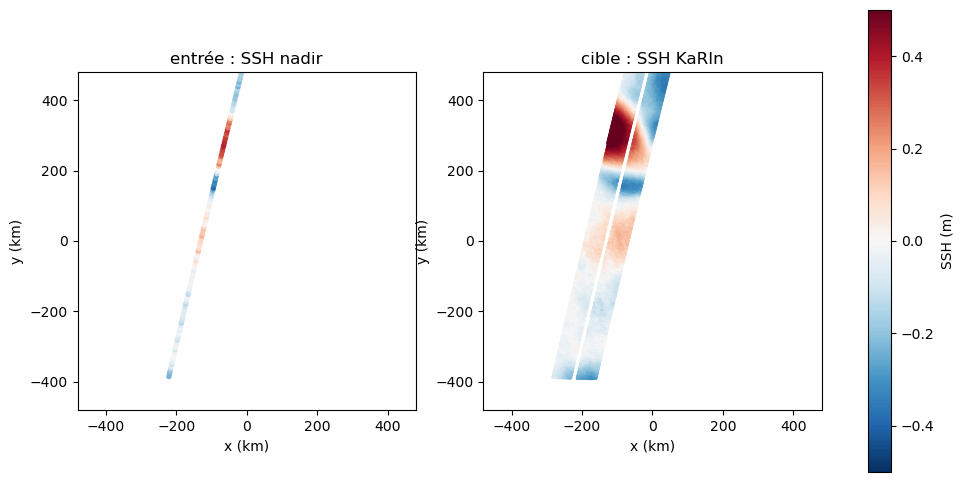

In [10]:
r = 24  # à choisir d'après le print
lon0, lat0 = centre_patch(coord_grids, r)
xn, yn, dn = projeter(nadir["lon"], nadir["lat"], lon0, lat0)
xk, yk, dk = projeter(karin["lon"], karin["lat"], lon0, lat0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# à gauche : ce que le réseau REÇOIT (nadir seul)
axes[0].scatter(xn[dn] / 1e3, yn[dn]/ 1e3, c=nadir["ssh"][dn], s=8, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[0].set_title("entrée : SSH nadir")

# à droite : ce qu'il doit RETROUVER (KaRIn)
im = axes[1].scatter(xk[dk]/ 1e3, yk[dk]/ 1e3, c=karin["ssh"][dk], s=1, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title("cible : SSH KaRIn")

for ax in axes:
    ax.set_xlim(-480, 480)
    ax.set_ylim(-480, 480)
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
plt.colorbar(im, ax=axes, label="SSH (m)")
plt.show()

In [11]:
from scipy import stats

L = 960e3        # taille de la feuille en m
n = 128        # nombre de cases par côté

moy_nadir, x_bords, y_bords, _ = stats.binned_statistic_2d(
    xn, yn, nadir["ssh"],
    statistic="mean", bins=n, range=[[-L/2, L/2], [-L/2, L/2]])

# TODO 1 : comme bin_ssh -> tourner l'image de 90° et remplacer les NaN par 0
# indices : np.rot90(...) ; image[np.isnan(image)] = 0
image_entree = np.rot90(moy_nadir)
image_entree[np.isnan(image_entree)] = 0

print("cases remplies :", (image_entree != 0).sum())

cases remplies : 119


In [12]:
moy_karin, _, _, _ = stats.binned_statistic_2d(
    xk, yk, karin["ssh"],
    statistic="mean", bins=n, range=[[-L/2, L/2], [-L/2, L/2]])

# le centre de chaque case, en m
x_centres = (x_bords[:-1] + x_bords[1:]) / 2
y_centres = (y_bords[:-1] + y_bords[1:]) / 2
X, Y = np.meshgrid(x_centres, y_centres, indexing="ij")   # même rangement que moy_karin

# TODO 2 : garder seulement les cases remplies (pas NaN)
remplie = np.isfinite(moy_karin)

cible = np.column_stack((X[remplie],      
                         Y[remplie],
                         moy_karin[remplie]))
print("cible :", cible.shape)

cible : (1909, 3)


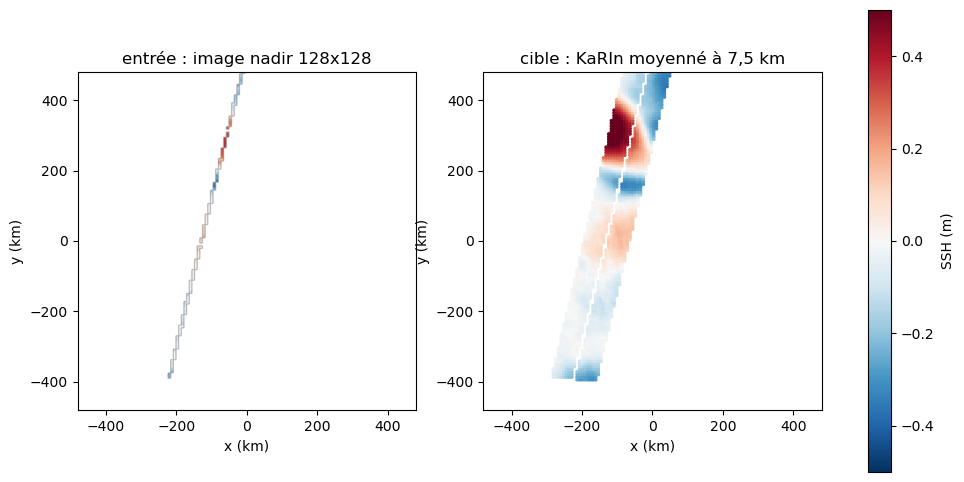

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(np.where(image_entree == 0, np.nan, image_entree),
               extent=[-480, 480, -480, 480], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[0].set_title("entrée : image nadir 128x128")

im = axes[1].scatter(cible[:, 0] / 1000, cible[:, 1] / 1000, c=cible[:, 2],
                     s=3, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title("cible : KaRIn moyenné à 7,5 km")

for ax in axes:
    ax.set_xlim(-480, 480)
    ax.set_ylim(-480, 480)
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
plt.colorbar(im, ax=axes, label="SSH (m)")
plt.show()

In [14]:
def boite_feuille(r):
    """Rectangle lon/lat qui entoure la feuille r (avec 0.1° de marge, comme NeurOST)."""
    lon_f = coord_grids[r, :, :, 0]
    lat_f = coord_grids[r, :, :, 1]
    return (lon_f.min() - 0.1, lon_f.max() + 0.1,
            lat_f.min() - 0.1, lat_f.max() + 0.1)


def faire_exemple(fichier, r, L=960e3, n=128):
    """Renvoie (image_entree, cible) pour un passage et une feuille."""

    # 1. extraire les points nadir et KaRIn autour de la feuille
    nadir, karin = extraire_passage(fichier, boite_feuille(r))

    # 2. les placer sur la feuille (en mètres), en ne gardant que les points dedans
    lon0, lat0 = centre_patch(coord_grids, r)
    xn, yn, dn = projeter(nadir["lon"], nadir["lat"], lon0, lat0, L)
    xk, yk, dk = projeter(karin["lon"], karin["lat"], lon0, lat0, L)
    xn, yn, ssh_n = xn[dn], yn[dn], nadir["ssh"][dn]
    xk, yk, ssh_k = xk[dk], yk[dk], karin["ssh"][dk]

    # 3. entrée : moyenne du nadir par case, rot90, NaN -> 0
    moy_nadir, x_bords, y_bords, _ = stats.binned_statistic_2d(
        xn, yn, ssh_n, statistic="mean", bins=n,
        range=[[-L/2, L/2], [-L/2, L/2]])
    image_entree = np.rot90(moy_nadir)
    image_entree[np.isnan(image_entree)] = 0

    # 4. cible : moyenne de KaRIn par case, on garde les cases remplies
    moy_karin, _, _, _ = stats.binned_statistic_2d(
        xk, yk, ssh_k, statistic="mean", bins=n,
        range=[[-L/2, L/2], [-L/2, L/2]])
    x_centres = (x_bords[:-1] + x_bords[1:]) / 2
    y_centres = (y_bords[:-1] + y_bords[1:]) / 2
    X, Y = np.meshgrid(x_centres, y_centres, indexing="ij")
    remplie = np.isfinite(moy_karin)

    cible = np.column_stack((X[remplie],
                             Y[remplie],
                             moy_karin[remplie]))

    return image_entree, cible

In [15]:
ligne = passages[(passages["cycle"] == 10) & (passages["passe"] == 451)].iloc[0]
image_entree, cible = faire_exemple(ligne["fichier"], 24)

print("cases nadir :", (image_entree != 0).sum())
print("cible :", cible.shape)

cases nadir : 131
cible : (2096, 3)


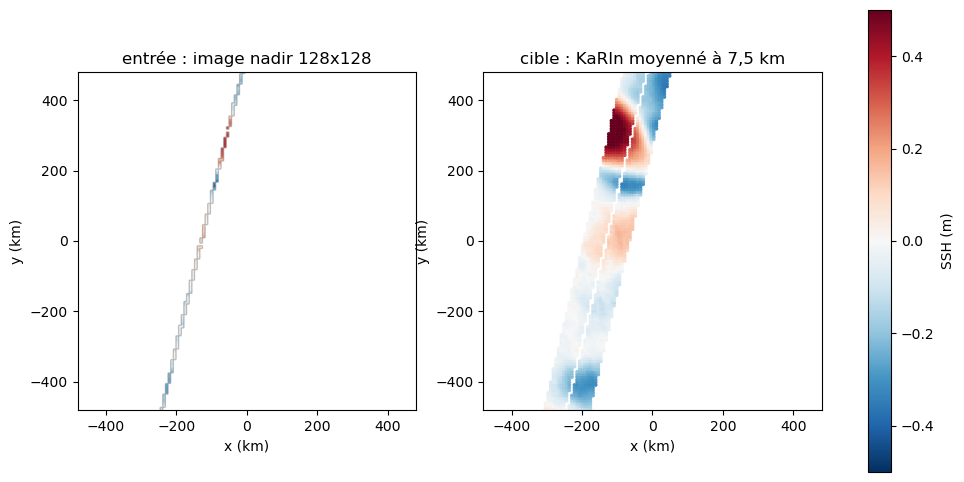

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(np.where(image_entree == 0, np.nan, image_entree),
               extent=[-480, 480, -480, 480], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[0].set_title("entrée : image nadir 128x128")

im = axes[1].scatter(cible[:, 0] / 1000, cible[:, 1] / 1000, c=cible[:, 2],
                     s=3, cmap="RdBu_r", vmin=-0.5, vmax=0.5)
axes[1].set_title("cible : KaRIn moyenné à 7,5 km")

for ax in axes:
    ax.set_xlim(-480, 480)
    ax.set_ylim(-480, 480)
    ax.set_aspect("equal")
    ax.set_xlabel("x (km)")
    ax.set_ylabel("y (km)")
plt.colorbar(im, ax=axes, label="SSH (m)")
plt.show()

In [23]:
r = 23
entrees = []      # liste d'images 128x128
cibles = []       # liste de tableaux (n_points, 3)
infos = []        # liste de dicts

for i, ligne in passages.iterrows():
#for i, ligne in passages.head(10).iterrows(): test 
    try:
        image_entree, cible = faire_exemple(ligne["fichier"], r)
    except Exception as e:
        print("ERREUR", ligne["fichier"], e)
        continue

    n_nadir = (image_entree != 0).sum()
    n_cible = cible.shape[0]

    # TODO 1 : si n_nadir == 0 ou n_cible == 0, passer au passage suivant
    # indice : continue
    if n_nadir == 0 : 
        continue

    entrees.append(image_entree)
    cibles.append(cible)
    infos.append({
        "fichier": ligne["fichier"],
        "cycle": ligne["cycle"],
        "passe": ligne["passe"],
        "t_debut": ligne["t_debut"],
        "n_nadir": n_nadir,
        "n_cible": n_cible,
    })

    if i % 50 == 0:
        print(i, "/", len(passages))

print(len(entrees), "exemples")

0 / 734
50 / 734
100 / 734
150 / 734
250 / 734
300 / 734
350 / 734
400 / 734
450 / 734
500 / 734
550 / 734
600 / 734
650 / 734
700 / 734
671 exemples


In [24]:
entrees = np.array(entrees, dtype=np.float32)          # (N, 128, 128)

# TODO 2 : longueur de la plus longue cible
# indice : max(...) sur les c.shape[0] de chaque cible
n_max = max([c.shape[0] for c in cibles])

cibles_tab = np.zeros((len(cibles), n_max, 3), dtype=np.float32)
for k, c in enumerate(cibles):
    cibles_tab[k, :c.shape[0], :] = c                  # le reste reste à 0

infos = pd.DataFrame(infos)

np.savez("exemples_GS_feuille23.npz", entrees=entrees, cibles=cibles_tab)
infos.to_csv("exemples_GS_feuille23.csv", index=False)

print("entrees :", entrees.shape)
print("cibles  :", cibles_tab.shape)

entrees : (671, 128, 128)
cibles  : (671, 2134, 3)


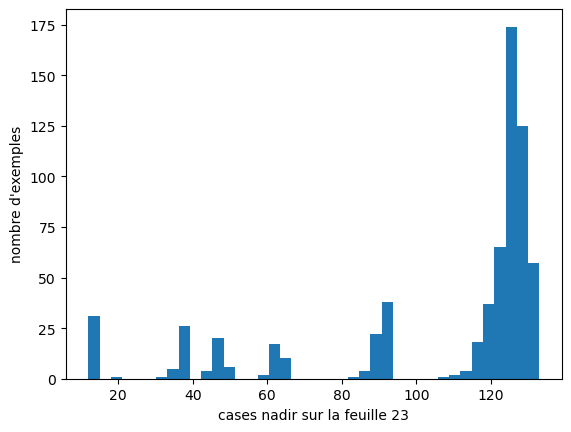

In [25]:
plt.hist(infos["n_nadir"], bins=40)
plt.xlabel("cases nadir sur la feuille 23")
plt.ylabel("nombre d'exemples")
plt.show()

In [26]:
debut = pd.Timestamp("2023-07-26")
motif = [("train", 105), ("trou", 21), ("val", 21),
         ("trou", 21), ("test", 42), ("trou", 21)]
longueur_motif = sum([duree for nom, duree in motif])     # 231

def quel_jeu(date):
    n = (date - debut).days
    position = n % longueur_motif
    for nom, duree in motif:
        if position < duree:
            return nom
        position = position - duree

In [29]:
infos = pd.read_csv("exemples_GS_feuille23.csv", parse_dates=["t_debut"])

# TODO 1 : colonne "jeu" = quel_jeu appliqué à chaque t_debut
# indice : infos["t_debut"].apply(quel_jeu)
infos["jeu"] = infos["t_debut"].apply(quel_jeu)

# TODO 2 : colonne "garde" = True si n_nadir >= 75
infos["garde"] = infos["n_nadir"] >= 75

print(infos[infos["garde"]]["jeu"].value_counts())

jeu
train    250
trou     150
test      96
val       52
Name: count, dtype: int64


In [30]:
infos.to_csv("exemples_GS_feuille23.csv", index=False)